# Klasifikasi Koin Rupiah - Model 1: Custom CNN (VGG-Style)

Notebook ini mengimplementasikan model **Custom Convolutional Neural Network (CNN)** berbasis arsitektur `Rupiah_CustomCNN (1).ipynb` (4 tahap konvolusi ganda / *Dual-Conv Blocks*, Batch Normalization, Max Pooling, Global Average Pooling, dan Dropout) yang disesuaikan untuk klasifikasi 4 pecahan koin Rupiah (**Rp 100**, **Rp 200**, **Rp 500**, **Rp 1.000**).

### Karakteristik Arsitektur:
- **4 Dual-Conv Blocks**: Masing-masing terdiri dari 2x (Conv2D 3x3 + BatchNorm + ReLU) diikuti MaxPooling 2x2.
  - Block 1: 3 -> 32 filter
  - Block 2: 32 -> 64 filter
  - Block 3: 64 -> 128 filter
  - Block 4: 128 -> 256 filter
- **Head Klasifikasi**: Global Average Pooling (GAP) -> Dense 128 (ReLU) -> Dropout (0.4) -> Dense 4 (Softmax/Logits)
- **Total Parameter**: 1.206.628 parameter
- **Dataset**: `dataset_koin_baru` dengan split terstratifikasi 70% Train, 15% Val, 15% Test dari `split.csv`.


## 1. Setup dan Konfigurasi


In [1]:
import os, json, time, random, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

NOTEBOOK_DIR = Path.cwd()
DIAGRAM_DIR  = NOTEBOOK_DIR.parent / "diagram"
DATASET_DIR  = NOTEBOOK_DIR.parent / "dataset_koin_baru"
DIAGRAM_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device yang digunakan: {DEVICE}")


Device yang digunakan: cpu


## 2. Memuat Split Dataset Terstratifikasi


In [1]:
df_split = pd.read_csv(NOTEBOOK_DIR / "split.csv")
CLASSES = sorted(df_split['label'].unique())
CLASS2IDX = {c: i for i, c in enumerate(CLASSES)}
IDX2CLASS = {i: c for c, i in CLASS2IDX.items()}

df_train = df_split[df_split['subset'] == 'train'].reset_index(drop=True)
df_val   = df_split[df_split['subset'] == 'val'].reset_index(drop=True)
df_test  = df_split[df_split['subset'] == 'test'].reset_index(drop=True)

print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")
print(f"Kelas: {CLASSES}")


Train: 414 | Val: 89 | Test: 89
Kelas: ['Rp100', 'Rp1000', 'Rp200', 'Rp500']


## 3. Preprocessing dan DataLoader


In [1]:
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class CoinDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        p = Path(row['path'])
        if not p.exists():
            p = DATASET_DIR / p.parent.name / p.name
        img = Image.open(p).convert('RGB')
        label = CLASS2IDX[row['label']]
        if self.transform:
            img = self.transform(img)
        return img, label

train_loader = DataLoader(CoinDataset(df_train, train_tf), batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(CoinDataset(df_val,   eval_tf),  batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(CoinDataset(df_test,  eval_tf),  batch_size=32, shuffle=False, num_workers=0)
print("DataLoader siap.")


DataLoader siap.


## 4. Perhitungan Bobot Kelas (Class Weights)


In [1]:
train_labels = [CLASS2IDX[l] for l in df_train['label']]
cw = compute_class_weight('balanced', classes=np.arange(len(CLASSES)), y=train_labels)
class_weights = torch.tensor(cw, dtype=torch.float32).to(DEVICE)
print("Bobot kelas untuk penyeimbang loss:")
for c, w in zip(CLASSES, cw):
    print(f"  {c:7s}: {w:.3f}")


Bobot kelas untuk penyeimbang loss:
  Rp100  : 1.015
  Rp1000 : 1.045
  Rp200  : 0.908
  Rp500  : 1.045


## 5. Definisi Arsitektur Custom CNN (VGG-Style)


In [1]:
class DualConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

    def forward(self, x):
        return self.block(x)

class RupiahCustomCNN(nn.Module):
    def __init__(self, num_classes=len(CLASSES), dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            DualConvBlock(3, 32),    # 224 -> 112
            DualConvBlock(32, 64),   # 112 -> 56
            DualConvBlock(64, 128),  # 56  -> 28
            DualConvBlock(128, 256), # 28  -> 14
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        return self.classifier(x)

model = RupiahCustomCNN(num_classes=len(CLASSES)).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model: RupiahCustomCNN | Total params: {total_params:,} | Trainable: {trainable_params:,}")


Model: RupiahCustomCNN | Total params: 1,206,628 | Trainable: 1,206,628


## 6. Proses Pelatihan Model


In [1]:
EPOCHS = 20
LR = 1e-3
PATIENCE = 6

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
best_val_acc = 0.0
patience_counter = 0
best_epoch = 0

best_model_path = DIAGRAM_DIR / "best_custom_cnn.pt"

print("Memulai training Custom CNN...")
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    t_loss, t_correct, t_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        t_loss += loss.item() * len(labels)
        preds = outputs.argmax(dim=1)
        t_correct += (preds == labels).sum().item()
        t_total += len(labels)

    train_loss = t_loss / t_total
    train_acc  = t_correct / t_total

    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            v_loss += loss.item() * len(labels)
            preds = outputs.argmax(dim=1)
            v_correct += (preds == labels).sum().item()
            v_total += len(labels)

    val_loss = v_loss / v_total
    val_acc  = v_correct / v_total

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]['lr']

    history['train_loss'].append(round(train_loss, 4))
    history['train_acc'].append(round(train_acc, 4))
    history['val_loss'].append(round(val_loss, 4))
    history['val_acc'].append(round(val_acc, 4))

    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}% | "
          f"LR: {current_lr:.2e}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"  --> Checkpoint terbaik disimpan (Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%)")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping di epoch {epoch}.")
            break

training_time_s = round(time.time() - t_start, 2)
print(f"Training selesai dalam {training_time_s} detik ({training_time_s/60:.2f} menit).")


Memulai training Custom CNN...
Epoch [01/20] Train Loss: 1.2659 Acc: 40.34% | Val Loss: 1.5171 Acc: 30.34% | LR: 1.00e-03
  --> Checkpoint terbaik disimpan (Val Loss: 1.5171, Val Acc: 30.34%)
Epoch [02/20] Train Loss: 1.1508 Acc: 49.52% | Val Loss: 1.0394 Acc: 56.18% | LR: 1.00e-03
  --> Checkpoint terbaik disimpan (Val Loss: 1.0394, Val Acc: 56.18%)
Epoch [03/20] Train Loss: 0.9771 Acc: 57.00% | Val Loss: 0.9155 Acc: 62.92% | LR: 1.00e-03
  --> Checkpoint terbaik disimpan (Val Loss: 0.9155, Val Acc: 62.92%)
Epoch [04/20] Train Loss: 0.9602 Acc: 54.59% | Val Loss: 1.1640 Acc: 57.30% | LR: 1.00e-03
Epoch [05/20] Train Loss: 0.8161 Acc: 67.87% | Val Loss: 1.2081 Acc: 58.43% | LR: 1.00e-03
Epoch [06/20] Train Loss: 0.8342 Acc: 63.04% | Val Loss: 0.9816 Acc: 65.17% | LR: 5.00e-04
Epoch [07/20] Train Loss: 0.7050 Acc: 68.84% | Val Loss: 0.7270 Acc: 70.79% | LR: 5.00e-04
  --> Checkpoint terbaik disimpan (Val Loss: 0.7270, Val Acc: 70.79%)
Epoch [08/20] Train Loss: 0.7039 Acc: 71.26% | Val L

## 7. Visualisasi Kurva Loss dan Akurasi


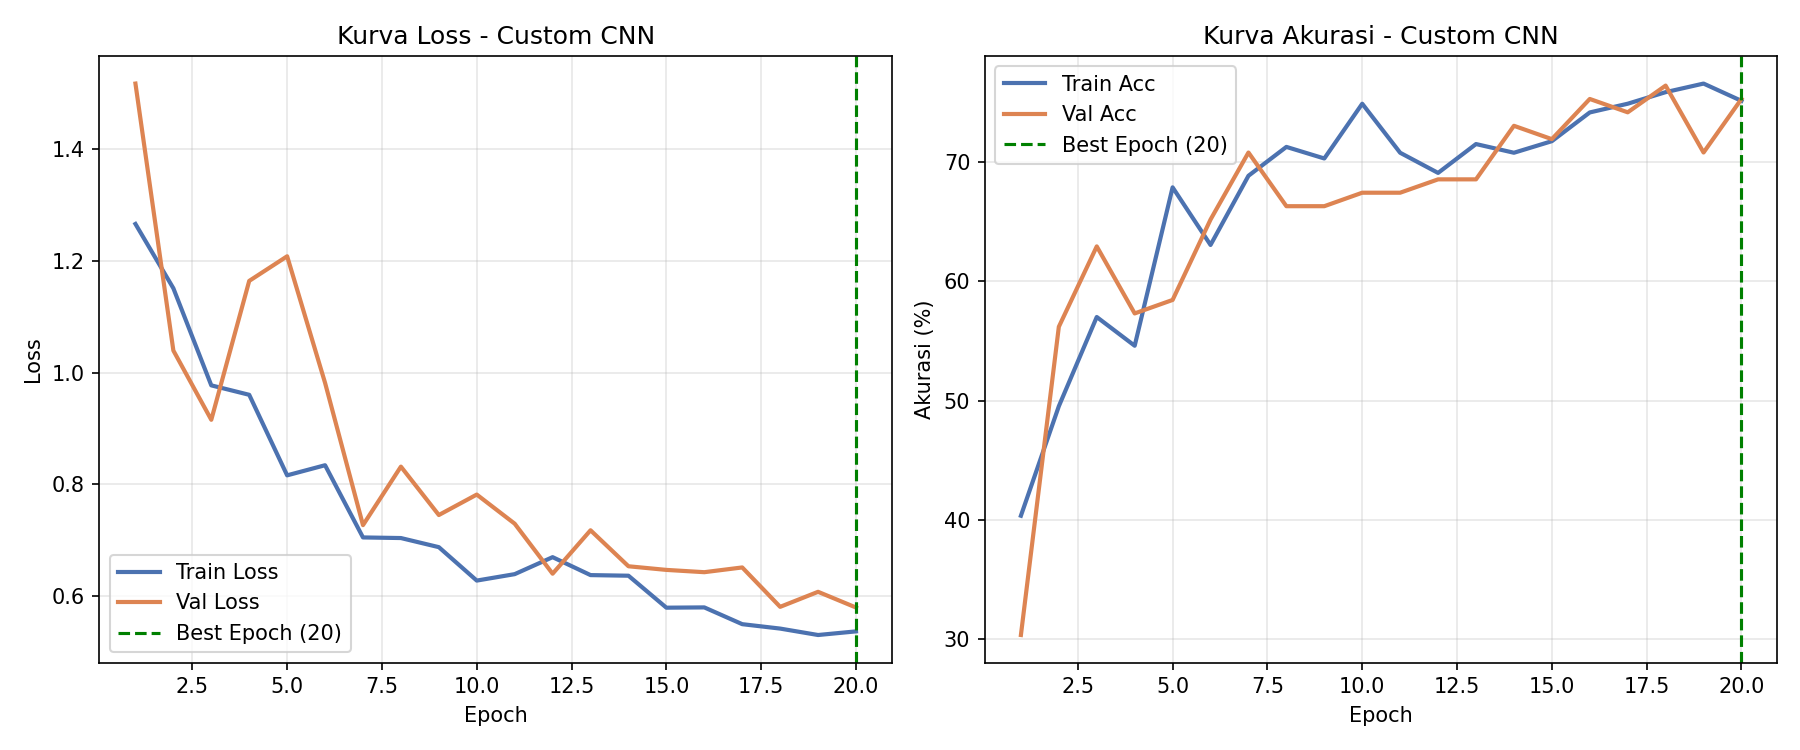

In [1]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
epochs_ran = list(range(1, len(history['train_loss']) + 1))

ax1.plot(epochs_ran, history['train_loss'], label='Train Loss', color='#4C72B0', lw=2)
ax1.plot(epochs_ran, history['val_loss'], label='Val Loss', color='#DD8452', lw=2)
ax1.axvline(best_epoch, color='green', ls='--', label=f'Best Epoch ({best_epoch})')
ax1.set_title('Kurva Loss - Custom CNN', fontsize=12)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_ran, [a * 100 for a in history['train_acc']], label='Train Acc', color='#4C72B0', lw=2)
ax2.plot(epochs_ran, [a * 100 for a in history['val_acc']], label='Val Acc', color='#DD8452', lw=2)
ax2.axvline(best_epoch, color='green', ls='--', label=f'Best Epoch ({best_epoch})')
ax2.set_title('Kurva Akurasi - Custom CNN', fontsize=12)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Akurasi (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIAGRAM_DIR / "kurva_custom_cnn.png", dpi=150)
plt.show()


## 8. Evaluasi pada Hold-Out Test Set


In [1]:
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
model.eval()

all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        all_probs.extend(probs)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

test_acc  = accuracy_score(all_labels, all_preds)
prec_macro = precision_score(all_labels, all_preds, average='macro', zero_division=0)
rec_macro  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
f1_macro   = f1_score(all_labels, all_preds, average='macro', zero_division=0)

print("=== HASIL EVALUASI TEST SET (Custom CNN) ===")
print(f"Accuracy         : {test_acc*100:.2f}%")
print(f"Precision (Macro): {prec_macro*100:.2f}%")
print(f"Recall (Macro)   : {rec_macro*100:.2f}%")
print(f"F1-Score (Macro) : {f1_macro*100:.2f}%
")
print(classification_report(all_labels, all_preds, target_names=CLASSES, digits=4))


=== HASIL EVALUASI TEST SET (Custom CNN) ===
Accuracy         : 73.03%
Precision (Macro): 75.02%
Recall (Macro)   : 74.53%
F1-Score (Macro) : 71.99%

              precision    recall  f1-score   support

       Rp100     0.8077    0.9545    0.8750        22
      Rp1000     0.8750    1.0000    0.9333        21
       Rp200     0.8182    0.3600    0.5000        25
       Rp500     0.5000    0.6667    0.5714        21

    accuracy                         0.7303        89
   macro avg     0.7502    0.7453    0.7199        89
weighted avg     0.7539    0.7303    0.7118        89


## 9. Visualisasi Confusion Matrix


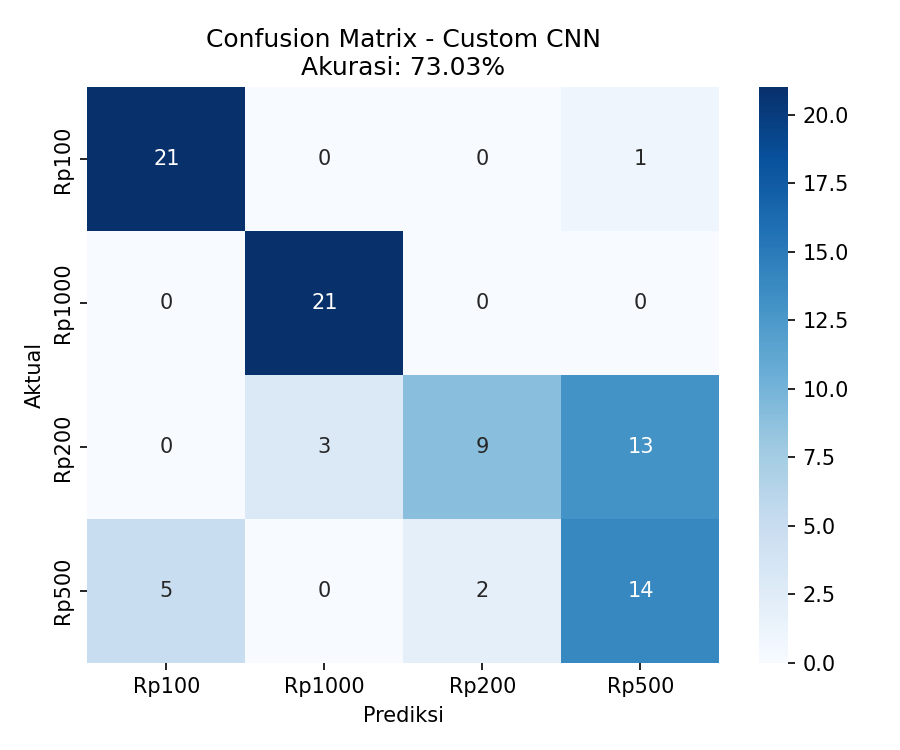

In [1]:
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title(f'Confusion Matrix - Custom CNN\nAkurasi: {test_acc*100:.2f}%', fontsize=12)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig(DIAGRAM_DIR / "cm_custom_cnn.png", dpi=150)
plt.show()


## 10. Benchmark Kecepatan Inferensi dan Efisiensi


In [1]:
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
with torch.no_grad():
    for _ in range(10): _ = model(dummy)
    t0 = time.time()
    for _ in range(50): _ = model(dummy)
    infer_time_ms = round((time.time() - t0) / 50 * 1000, 2)

model_size_mb = round(best_model_path.stat().st_size / (1024 * 1024), 2)
print(f"Waktu inferensi rata-rata: {infer_time_ms} ms/gambar")
print(f"Ukuran file checkpoint   : {model_size_mb} MB")


Waktu inferensi rata-rata: 27.64 ms/gambar
Ukuran file checkpoint   : 4.63 MB


## 11. Analisis Contoh Gambar Salah Prediksi


Jumlah salah prediksi: 24 dari 89 data test


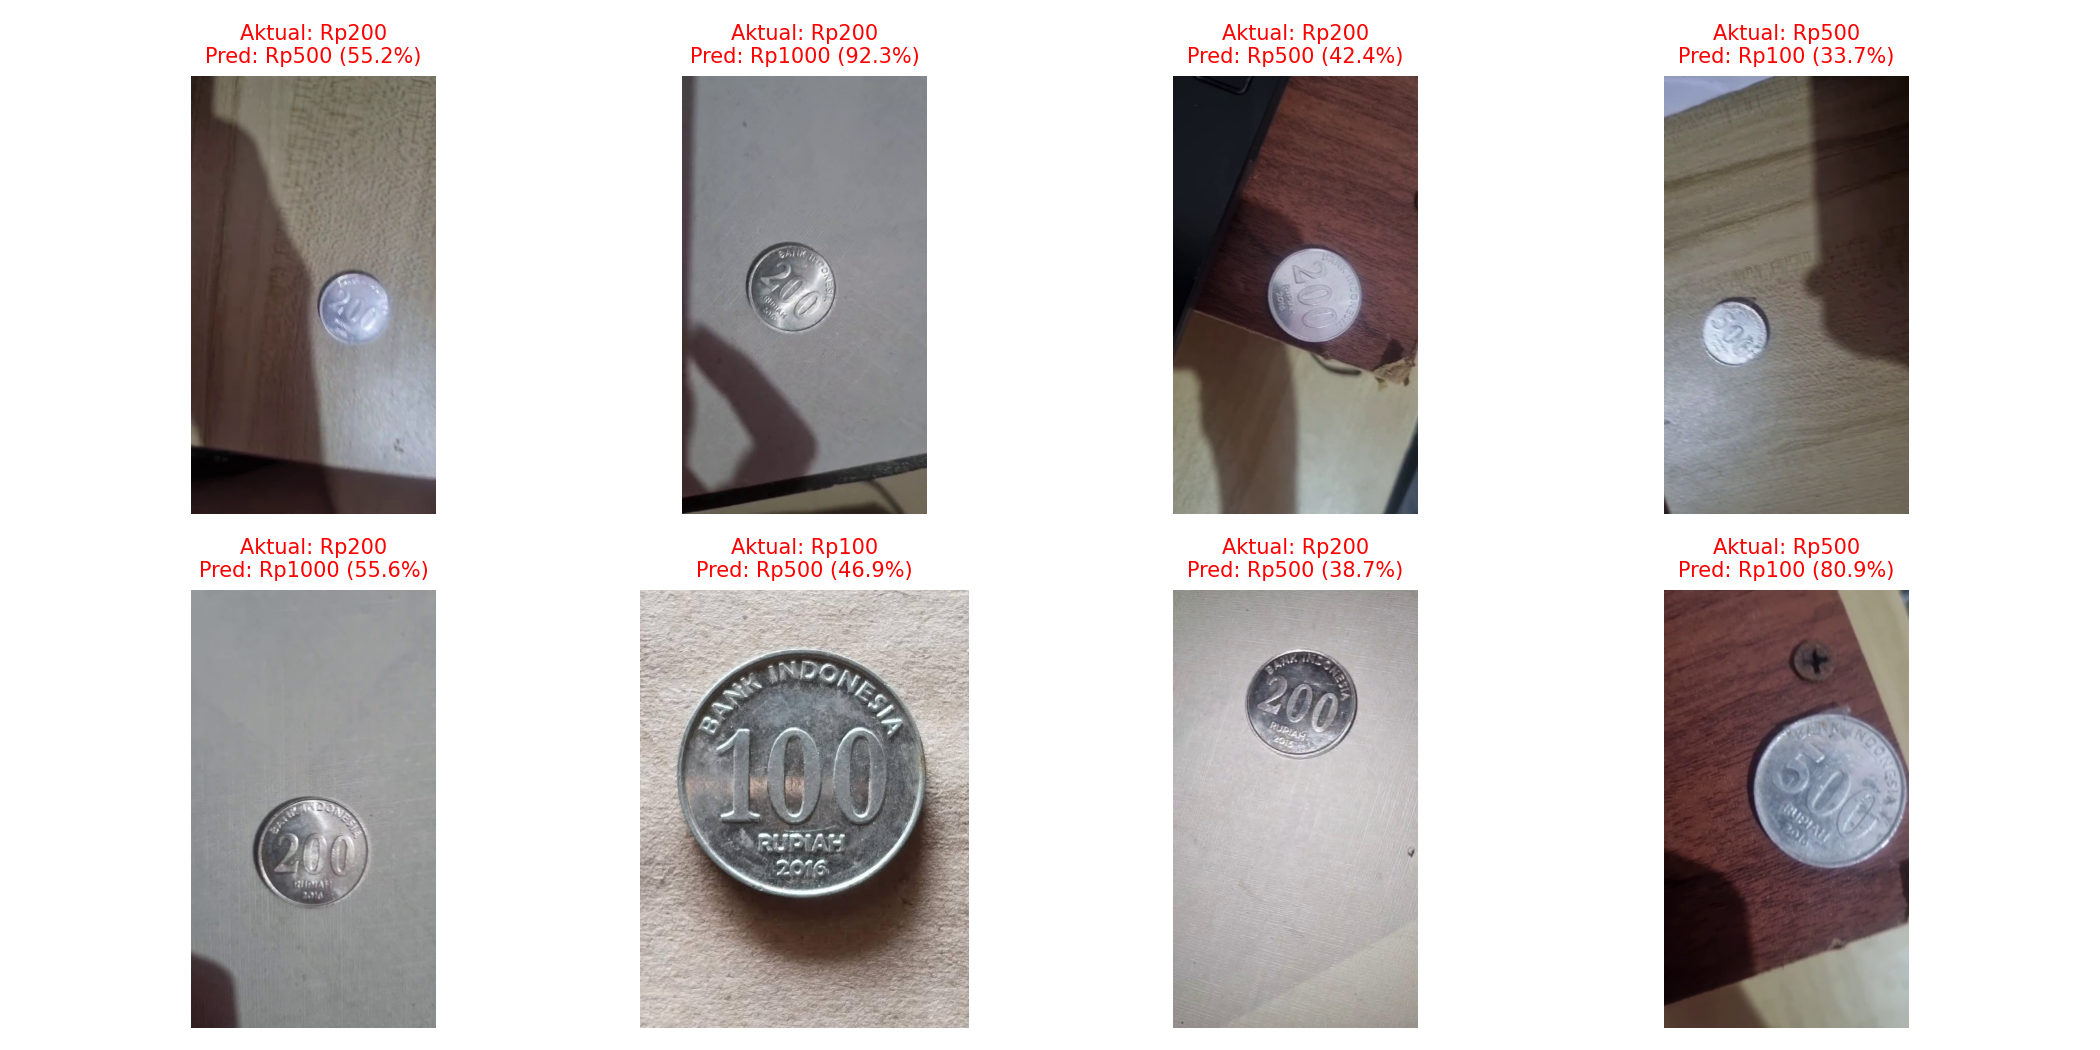

In [1]:
wrong_idxs = np.where(all_preds != all_labels)[0]
print(f"Jumlah salah prediksi: {len(wrong_idxs)} dari {len(all_labels)} data test")

if len(wrong_idxs) > 0:
    show_idxs = wrong_idxs[:min(8, len(wrong_idxs))]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()
    for i, idx in enumerate(show_idxs):
        row = df_test.iloc[idx]
        p = Path(row['path'])
        if not p.exists():
            p = DATASET_DIR / p.parent.name / p.name
        img_raw = Image.open(p).convert('RGB')
        true_cls = CLASSES[all_labels[idx]]
        pred_cls = CLASSES[all_preds[idx]]
        conf = all_probs[idx][all_preds[idx]] * 100

        axes[i].imshow(img_raw)
        axes[i].set_title(f"Aktual: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", color='red', fontsize=10)
        axes[i].axis('off')

    for j in range(len(show_idxs), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(DIAGRAM_DIR / "misclassified_custom_cnn.png", dpi=150)
    plt.show()


## 12. Penyimpanan Metrik Evaluasi


In [1]:
f1_per_class = f1_score(all_labels, all_preds, average=None, zero_division=0).tolist()
prec_per_class = precision_score(all_labels, all_preds, average=None, zero_division=0).tolist()
rec_per_class = recall_score(all_labels, all_preds, average=None, zero_division=0).tolist()

per_class_metrics = {}
for i, cls_name in enumerate(CLASSES):
    per_class_metrics[cls_name] = {
        'precision': round(prec_per_class[i], 4),
        'recall':    round(rec_per_class[i], 4),
        'f1':        round(f1_per_class[i], 4),
        'support':   int((all_labels == i).sum())
    }

metrics = {
    'model': 'custom_cnn',
    'display_name': 'Custom CNN (VGG-style)',
    'accuracy': float(test_acc),
    'precision_macro': float(prec_macro),
    'recall_macro': float(rec_macro),
    'f1_macro': float(f1_macro),
    'per_class': per_class_metrics,
    'confusion_matrix': cm.tolist(),
    'total_params': total_params,
    'model_size_mb': model_size_mb,
    'infer_time_ms': infer_time_ms,
    'training_time_s': training_time_s,
    'best_epoch': best_epoch,
    'history': history,
    'classes': CLASSES,
    'hyperparams': {
        'epochs': EPOCHS,
        'batch_size': 32,
        'lr': LR,
        'optimizer': 'Adam',
        'patience': PATIENCE,
        'img_size': IMG_SIZE,
        'architecture': '4 Dual-Conv Blocks + BN + GAP + Dense(128) + Dropout(0.4)'
    }
}

with open(DIAGRAM_DIR / "metrics_custom_cnn.json", 'w') as f:
    json.dump(metrics, f, indent=2)

print("Metrik berhasil disimpan ke diagram/metrics_custom_cnn.json")


Metrik berhasil disimpan ke diagram/metrics_custom_cnn.json
